In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (días) se adjunta. Durante la revisión del plan se descubre que la actividad F no puede empezar hasta que termine E: hay que añadir esa prelación.

In [4]:
pregunta_1 = "1. Construya la matriz de rutas $R$ del proyecto original y calcule $\\tau = \\lVert R\\,t \\rVert_\\infty$.  "
pregunta_2 = "2. Razone, sin recalcular todo, qué le ocurre a $R$ al añadir la prelación E → F: ¿qué rutas dejan de serlo (quedan «absorbidas» por otras más largas) y qué rutas nuevas aparecen?  "
pregunta_3 = "3. Construya la matriz de rutas del proyecto modificado y compruebe su razonamiento. Calcule el nuevo τ y la nueva ruta crítica.  "
pregunta_4 = "4. ¿Puede añadir una prelación *reducir* τ? ¿Y aumentar el número de rutas? Justifíquelo con $R$.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Construya la matriz de rutas $R$ del proyecto original y calcule $\tau = \lVert R\,t \rVert_\infty$.  

2. Razone, sin recalcular todo, qué le ocurre a $R$ al añadir la prelación E → F: ¿qué rutas dejan de serlo (quedan «absorbidas» por otras más largas) y qué rutas nuevas aparecen?  

3. Construya la matriz de rutas del proyecto modificado y compruebe su razonamiento. Calcule el nuevo τ y la nueva ruta crítica.  

4. ¿Puede añadir una prelación *reducir* τ? ¿Y aumentar el número de rutas? Justifíquelo con $R$.  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 7       ),
    ('B'     , '---'      , 2       ),
    ('C'     , 'A,B'      , 6       ),
    ('D'     , 'B'        , 2       ),
    ('E'     , 'C'        , 3       ),
    ('F'     , 'C,D'      , 8       ),
    ('G'     , 'E,F'      , 8       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,7
B,---,2
C,"A,B",6
D,B,2
E,C,3
F,"C,D",8
G,"E,F",8


# Resolución

In [6]:
def bmatrix(a, dec=0):
    """Matriz LaTeX (bmatrix) a partir de un DataFrame o array."""
    a = np.asarray(getattr(a, 'values', a), dtype=float)
    if a.ndim == 1:
        a = a.reshape(-1, 1)
    filas = [' & '.join(f'{x:.{dec}f}' for x in fila) + r'\\' for fila in a]
    return r'\begin{bmatrix}' + '\n' + '\n'.join(filas) + '\n' + r'\end{bmatrix}'

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
R = proyecto.path_matrix(dummies=False)
t = datos_proyecto['duration'][R.columns]

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Construya la matriz de rutas $R$ del proyecto original y calcule $\tau = \lVert R\,t \rVert_\infty$.  

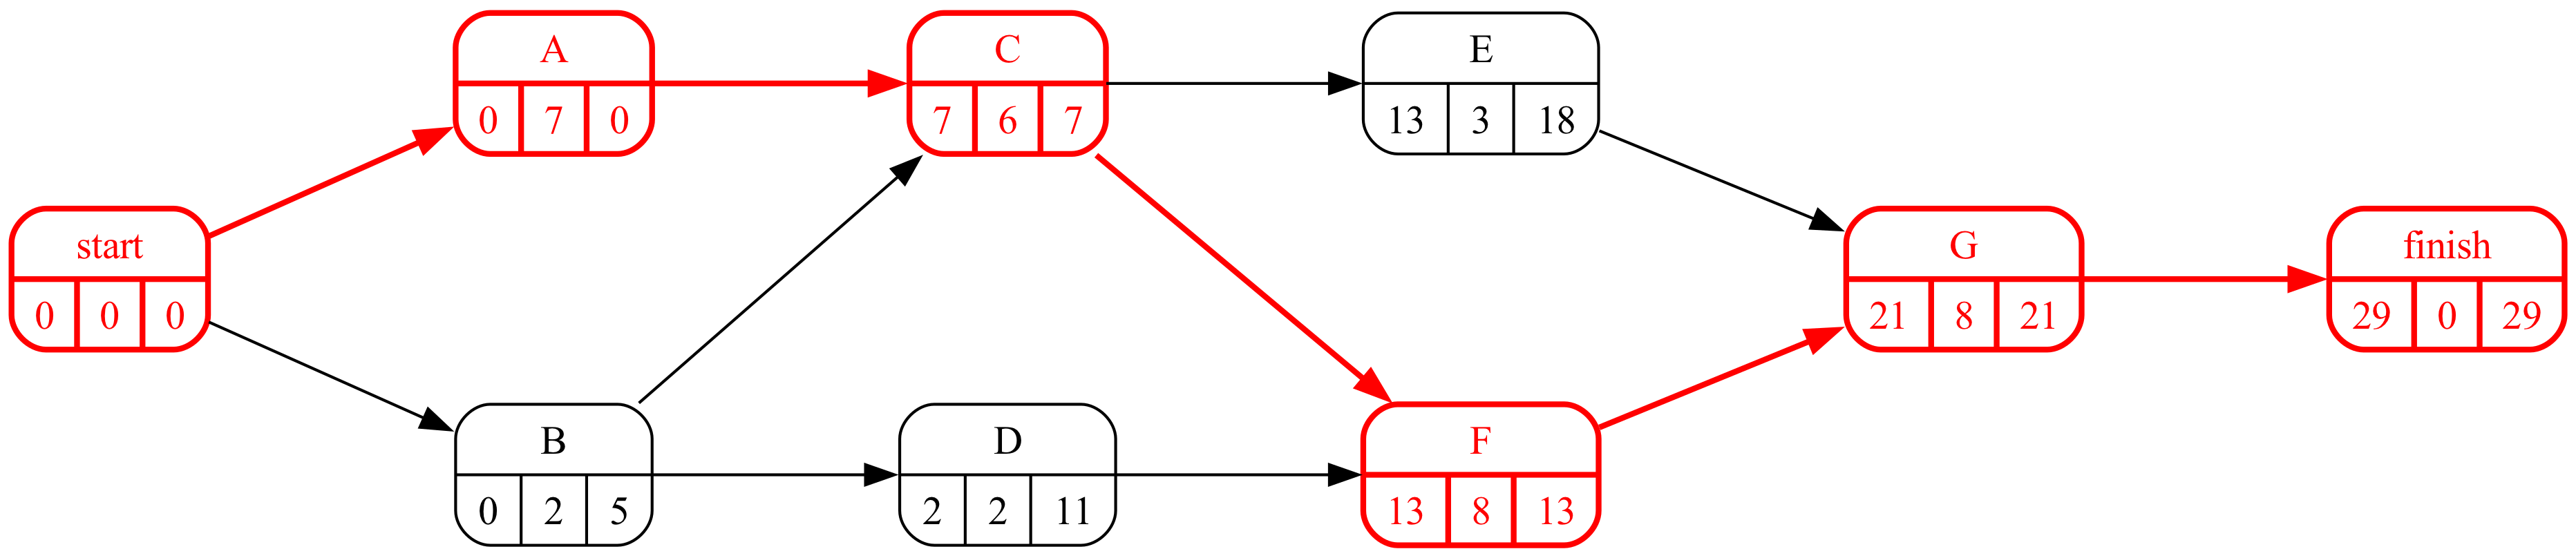

In [9]:
#| fig-cap: "Grafo Roy original"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso (avance con los botones):

In [ ]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

In [10]:
#| tbl-cap: "Matriz de rutas original"
#| label: tbl-R
rutas = {r: ' - '.join(acts) for r, acts in proyecto.paths(dummies=False).items()}
Rt = R @ t
pd.DataFrame({'actividades': rutas, 'R·t': Rt})

,actividades,R·t
Route_1,A - C - E - G,24
Route_2,A - C - F - G,29
Route_3,B - C - E - G,19
Route_4,B - C - F - G,24
Route_5,B - D - F - G,20


In [11]:
tau = float(Rt.max())
Markdown(f'τ = ‖R·t‖∞ = {tau:.0f} (ruta {Rt.idxmax()}: {rutas[Rt.idxmax()]}).')

τ = ‖R·t‖∞ = 29 (ruta Route_2: A - C - F - G).

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Razone, sin recalcular todo, qué le ocurre a $R$ al añadir la prelación E → F: ¿qué rutas dejan de serlo (quedan «absorbidas» por otras más largas) y qué rutas nuevas aparecen?  

Añadir E → F crea un arco nuevo. Aparecen rutas nuevas: las que llegan hasta E por cualquier camino (*prefijos*), saltan a F y continúan desde F hasta el final (*sufijos*): hasta «número de prefijos × número de sufijos» filas nuevas. Las rutas antiguas siguen existiendo, salvo una excepción: si alguna prelación antigua q → F se vuelve redundante (porque q es antecesora de E), el cuadro depurado la elimina y las rutas que usaban ese salto directo desaparecen, absorbidas por rutas nuevas que pasan por q, …, E, F y son más largas. Y si E era final (o F inicial), las rutas que terminaban en E (o empezaban en F) dejan de serlo: se prolongan a través del nuevo arco. En la práctica $R$ gana filas y puede perder alguna.

In [13]:
p, a = 'E', 'F'
prefijos = [r for r in R.index if R.loc[r, p] == 1]
sufijos = [r for r in R.index if R.loc[r, a] == 1]
Markdown(f'Rutas por {p}: {", ".join(prefijos)}; rutas por {a}: {", ".join(sufijos)}. '
         f'Se esperan hasta {len(prefijos)} × {len(sufijos)} = {len(prefijos) * len(sufijos)} combinaciones prefijo-sufijo (menos las repetidas).')

Rutas por E: Route_1, Route_3; rutas por F: Route_2, Route_4, Route_5. Se esperan hasta 2 × 3 = 6 combinaciones prefijo-sufijo (menos las repetidas).

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. Construya la matriz de rutas del proyecto modificado y compruebe su razonamiento. Calcule el nuevo τ y la nueva ruta crítica.  

In [15]:
#| tbl-cap: "Cuadro de prelaciones modificado"
#| label: tbl-datosModificado
datos_modificados = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 7       ),
    ('B'     , '---'      , 2       ),
    ('C'     , 'A,B'      , 6       ),
    ('D'     , 'B'        , 2       ),
    ('E'     , 'C'        , 3       ),
    ('F'     , 'D,E'      , 8       ),
    ('G'     , 'F'        , 8       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_modificados

,predecessor,duration
activity,,
A,---,7
B,---,2
C,"A,B",6
D,B,2
E,C,3
F,"D,E",8
G,F,8


In [16]:
prelaciones2 = PredecessorTable.from_dataframe_of_strings(datos_modificados, activity='activity', predecessor='predecessor')
proyecto2 = prelaciones2.create_project()
R2 = proyecto2.path_matrix(dummies=False)
t2 = datos_modificados['duration'][R2.columns]
rutas2 = {r: ' - '.join(acts) for r, acts in proyecto2.paths(dummies=False).items()}
R2t = R2 @ t2
pd.DataFrame({'actividades': rutas2, 'R·t': R2t})

,actividades,R·t
Route_1,A - C - E - F - G,32
Route_2,B - C - E - F - G,27
Route_3,B - D - F - G,20


In [17]:
conj1 = {frozenset(R.columns[R.loc[r] == 1]) for r in R.index}
conj2 = {frozenset(R2.columns[R2.loc[r] == 1]) for r in R2.index}
perdidas = [rutas[r] for r in R.index if frozenset(R.columns[R.loc[r] == 1]) in conj1 - conj2]
nuevas = [rutas2[r] for r in R2.index if frozenset(R2.columns[R2.loc[r] == 1]) in conj2 - conj1]
tau2 = float(R2t.max())
Markdown(f'''Rutas que desaparecen: {'; '.join(perdidas) or 'ninguna'}.\n\nRutas nuevas: {'; '.join(nuevas) or 'ninguna'}.\n\nNuevo τ = {tau2:.0f} (antes {tau:.0f}); ruta crítica {R2t.idxmax()}: {rutas2[R2t.idxmax()]}.''')

Rutas que desaparecen: A - C - E - G; A - C - F - G; B - C - E - G; B - C - F - G.

Rutas nuevas: A - C - E - F - G; B - C - E - F - G.

Nuevo τ = 32 (antes 29); ruta crítica Route_1: A - C - E - F - G.

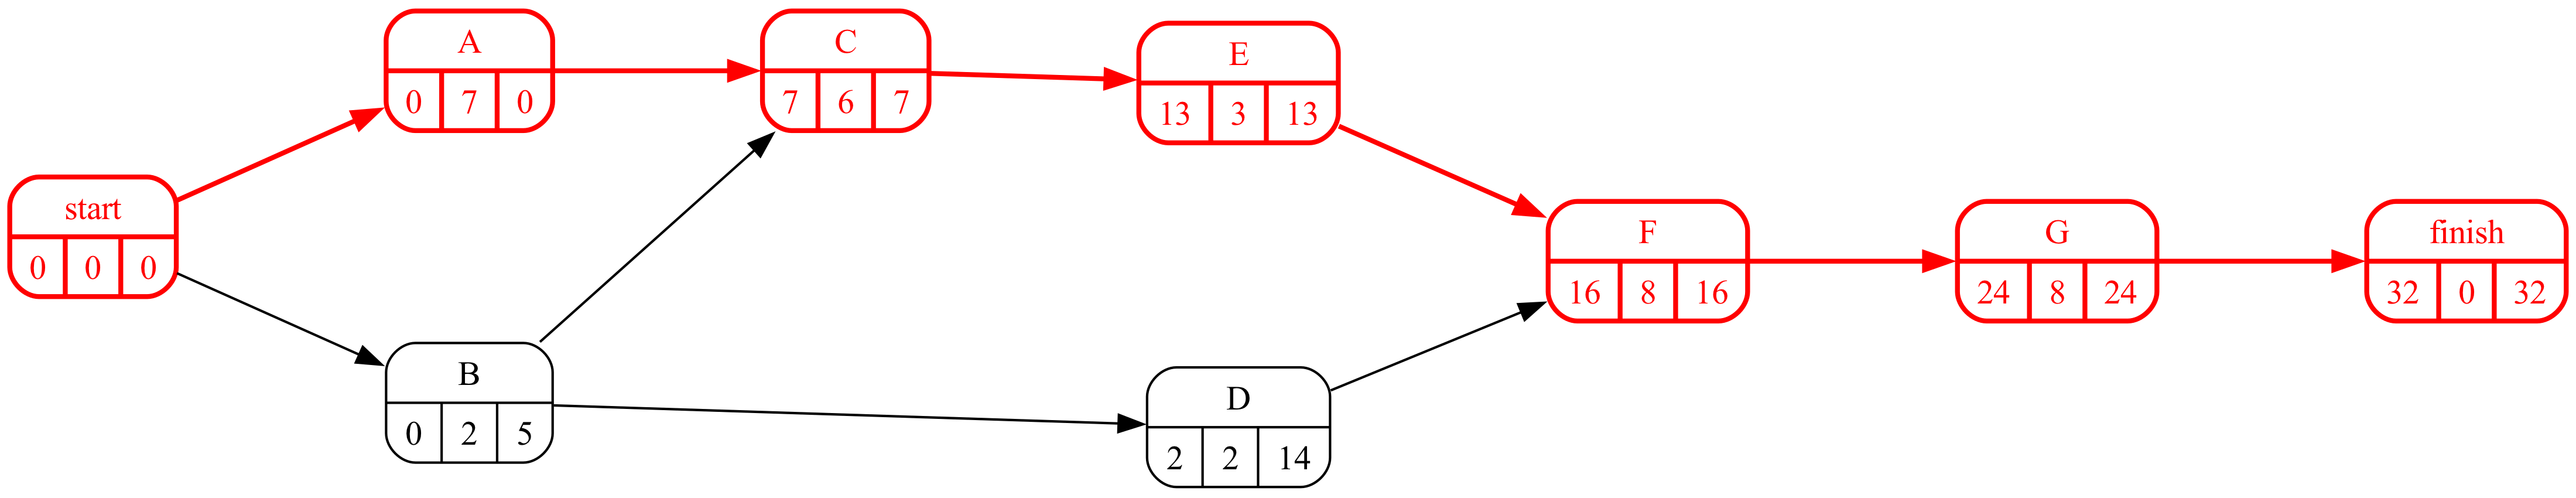

In [18]:
#| fig-cap: "Grafo Roy modificado"
#| label: fig-pert2
proyecto2.roy(durations=datos_modificados['duration'], ranksep=1.2, nodesep=1.2)

## Apartado 4

In [19]:
display(Markdown(pregunta_4))

4. ¿Puede añadir una prelación *reducir* τ? ¿Y aumentar el número de rutas? Justifíquelo con $R$.  

Añadir una prelación nunca reduce τ: cada ruta nueva contiene como subconjunto de actividades a alguna combinación que ya restringía el proyecto, y las rutas que desaparecen son las contenidas en alguna ruta nueva (su suma de duraciones es menor o igual). Formalmente, para cada fila antigua $r$ existe una fila nueva $r'$ con $R'_{r'} \ge R_r$ componente a componente, luego $\max R' t \ge \max R t$. El número de rutas sí puede crecer (producto de prefijos por sufijos) o decrecer (si muchas quedan absorbidas): $R$ no es monótona en tamaño, sólo en lo que restringe.